In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 2000

products = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet", "Headphones", "Monitor"],
    "category": [
        "Electronics", "Electronics", "Electronics",
        "Accessories", "Electronics"
    ],
    "unit_price": [55000, 25000, 18000, 2500, 14000]
})

product_idx = rng.integers(0, len(products), n)
dates = pd.to_datetime("2025-01-01") + pd.to_timedelta(
    rng.integers(0, 365, n), unit="D"
)

df = pd.DataFrame({
    "order_id": [f"ORD{i:05d}" for i in range(1, n + 1)],
    "order_date": dates,
    "customer_id": [f"C{v:04d}" for v in rng.integers(1, 500, n)],
    "region": rng.choice(
        ["South", "North", "East", "West"], n
    ),
    "product": products["product"].iloc[product_idx].to_numpy(),
    "category": products["category"].iloc[product_idx].to_numpy(),
    "unit_price": products["unit_price"].iloc[product_idx].to_numpy(),
    "quantity": rng.integers(1, 8, n),
    "discount": rng.choice([0, 0.05, 0.10, 0.15], n),
    "status": rng.choice(
        ["Completed", "Pending", "Cancelled"],
        n,
        p=[0.80, 0.12, 0.08]
    )
})

df["gross_revenue"] = df["unit_price"] * df["quantity"]
df["net_revenue"] = df["gross_revenue"] * (1 - df["discount"])

df.to_csv("sales.csv", index=False)
display(df.head())
print("Dataset shape:", df.shape)

,order_id,order_date,customer_id,region,product,category,unit_price,quantity,discount,status,gross_revenue,net_revenue
0,ORD00001,2025-11-17,C0159,East,Laptop,Electronics,55000,5,0.05,Completed,275000,261250.0
1,ORD00002,2025-01-23,C0421,West,Headphones,Accessories,2500,6,0.00,Completed,15000,15000.0
2,ORD00003,2025-05-26,C0018,East,Headphones,Accessories,2500,2,0.10,Completed,5000,4500.0
3,ORD00004,2025-06-17,C0223,East,Tablet,Electronics,18000,3,0.10,Completed,54000,48600.0
4,ORD00005,2025-10-19,C0400,North,Tablet,Electronics,18000,7,0.05,Completed,126000,119700.0


Dataset shape: (2000, 12)


In [2]:
print("Date range:", df["order_date"].min(), "to", df["order_date"].max())
print("Unique customers:", df["customer_id"].nunique())
print("Unique products:", df["product"].nunique())

display(df.describe(include="all").T)
display(df["status"].value_counts().to_frame("orders"))

Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Unique customers: 491
Unique products: 5


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,2000,2000,ORD00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2000,NaN,NaN,NaN,2025-07-02 20:44:09.600000,2025-01-01 00:00:00,2025-03-31 00:00:00,2025-06-30 00:00:00,2025-10-02 00:00:00,2025-12-31 00:00:00,NaN
customer_id,2000,491,C0176,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2000,4,South,531,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,2000,5,Tablet,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2000,2,Electronics,1606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_price,2000.0,NaN,NaN,NaN,23172.0,2500.0,14000.0,18000.0,25000.0,55000.0,17879.121832
quantity,2000.0,NaN,NaN,NaN,4.009,1.0,2.0,4.0,6.0,7.0,1.965668
discount,2000.0,NaN,NaN,NaN,0.076025,0.0,0.05,0.1,0.1,0.15,0.055525
status,2000,3,Completed,1604,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,orders
status,
Completed,1604
Pending,244
Cancelled,152


,net_revenue
region,
South,47795850.0
East,45992475.0
North,43478175.0
West,38494750.0


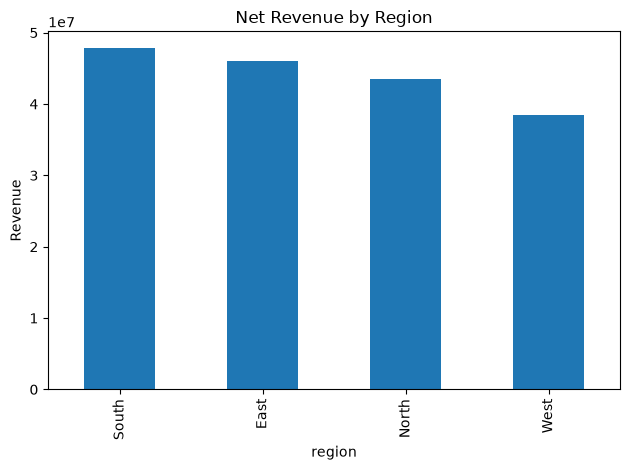

In [8]:
region_revenue = (
    df.groupby("region")["net_revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(region_revenue.to_frame("net_revenue"))

region_revenue.plot(kind="bar", title="Net Revenue by Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

,orders,units_sold,revenue,average_order_revenue
product,,,,
Laptop,419,1786,90763750.0,216619.93
Phone,364,1463,33818750.0,92908.65
Tablet,423,1667,27684000.0,65446.81
Monitor,400,1540,19876500.0,49691.25
Headphones,394,1562,3618250.0,9183.38


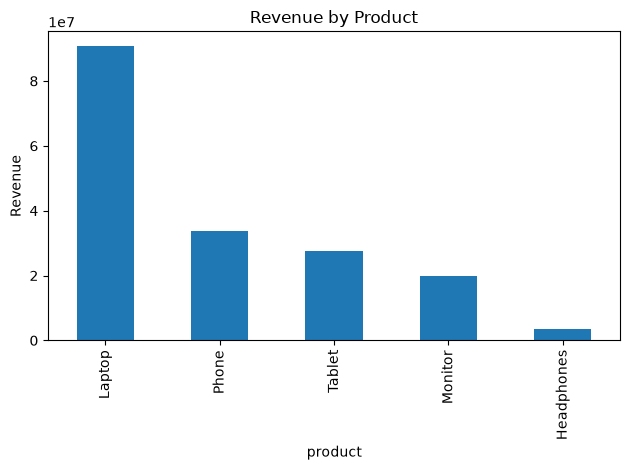

In [4]:
product_performance = df.groupby("product").agg(
    orders=("order_id", "nunique"),
    units_sold=("quantity", "sum"),
    revenue=("net_revenue", "sum"),
    average_order_revenue=("net_revenue", "mean")
).sort_values("revenue", ascending=False)

display(product_performance.round(2))

product_performance["revenue"].plot(
    kind="bar", title="Revenue by Product"
)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

,net_revenue
order_date,
2025-01-01,15399900.0
2025-02-01,13227400.0
2025-03-01,17265750.0
2025-04-01,11489575.0
2025-05-01,14592650.0
2025-06-01,13185950.0
2025-07-01,15512500.0
2025-08-01,13337775.0
2025-09-01,14784325.0


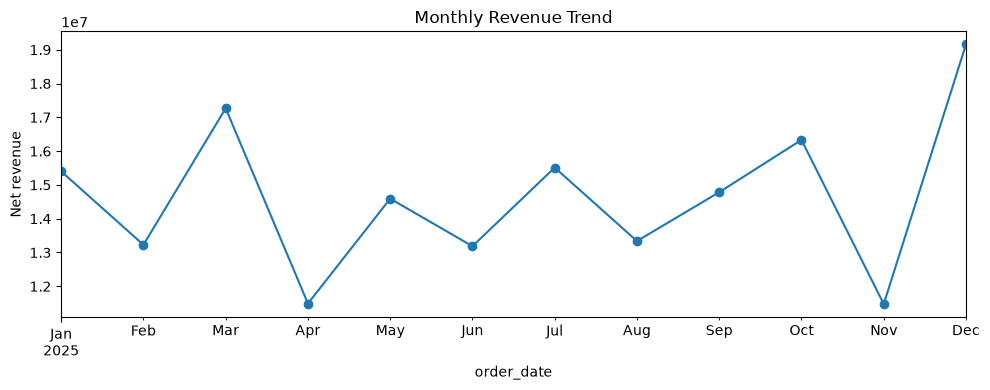

In [5]:
monthly_revenue = (
    df.set_index("order_date")
    .sort_index()
    .resample("MS")["net_revenue"]
    .sum()
)

display(monthly_revenue.to_frame())

monthly_revenue.plot(
    marker="o", title="Monthly Revenue Trend", figsize=(10, 4)
)
plt.ylabel("Net revenue")
plt.tight_layout()
plt.show()

In [9]:
customer_summary = df.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_spend=("net_revenue", "sum"),
    average_order_value=("net_revenue", "mean")
)

customer_summary = customer_summary.sort_values(
    "total_spend", ascending=False
)

display(customer_summary.head(10))

,total_orders,total_spend,average_order_value
customer_id,,,
C0189,5,1395250.0,279050.000000
C0165,10,1370625.0,137062.500000
C0456,10,1201175.0,120117.500000
C0051,8,1184750.0,148093.750000
C0030,6,1134350.0,189058.333333
C0464,9,1120250.0,124472.222222
C0378,8,1098100.0,137262.500000
C0495,10,1049475.0,104947.500000
C0269,8,1049250.0,131156.250000


In [10]:
status_summary = df.groupby("status").agg(
    order_count=("order_id", "nunique"),
    gross_revenue=("gross_revenue", "sum"),
    net_revenue=("net_revenue", "sum")
)

status_summary["order_percentage"] = (
    status_summary["order_count"] / status_summary["order_count"].sum() * 100
).round(2)

display(status_summary.round(2))

,order_count,gross_revenue,net_revenue,order_percentage
status,,,,
Cancelled,152,13353000,12422400.0,7.6
Completed,1604,153259500,141467100.0,80.2
Pending,244,23663500,21871750.0,12.2


In [11]:
quality_report = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
    "dtype": df.dtypes.astype(str)
})

display(quality_report)
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Negative quantities:", df["quantity"].lt(0).sum())
print("Negative revenue:", df["net_revenue"].lt(0).sum())

,missing_values,unique_values,dtype
order_id,0,2000,str
order_date,0,364,datetime64[us]
customer_id,0,491,str
region,0,4,str
product,0,5,str
category,0,2,str
unit_price,0,5,int64
quantity,0,7,int64
discount,0,4,float64
status,0,3,str


Duplicate order IDs: 0
Negative quantities: 0
Negative revenue: 0


In [12]:
from pathlib import Path

output = Path("reports")
output.mkdir(exist_ok=True)

region_revenue.to_csv(output / "region_revenue.csv")
product_performance.to_csv(output / "product_performance.csv")
monthly_revenue.to_csv(output / "monthly_revenue.csv")
customer_summary.to_csv(output / "customer_summary.csv")
quality_report.to_csv(output / "data_quality_report.csv")

print("Reports saved to:", output.resolve())

Reports saved to: E:\Linkific\Day 5\reports
